# Team Rhone: Wine Review Authorship Models

Predicting the reviewer of a wine review from its text using classic, interpretable text features and classifiers.


## 1. Data Setup


In [13]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

# --------------------------- SETTINGS ---------------------------
INPUT_FILE = "winemag-data-130k-v2.csv"
MIN_REVIEWS_PER_AUTHOR = 300
N_AUTHORS = 20
REVIEWS_PER_AUTHOR = 300
RANDOM_STATE = 4401

# Keep only text-author pairs needed for authorship prediction.
df = pd.read_csv(INPUT_FILE)
model_data = df.dropna(subset=["taster_name", "description"]).copy()
model_data["taster_name"] = model_data["taster_name"].astype(str).str.strip()
model_data["description"] = model_data["description"].astype(str).str.strip()
model_data = model_data[(model_data["taster_name"] != "") & (model_data["description"] != "")].copy()

# Remove EVERY repeated description before sampling. This prevents an identical review
# from leaking into both the training and test sets.
rows_before_deduplication = len(model_data)
description_frequency = model_data["description"].value_counts()
model_data = model_data[model_data["description"].map(description_frequency).eq(1)].copy()
print(f"Removed {rows_before_deduplication - len(model_data):,} rows with duplicate review text.")

# Select prolific reviewers and use the same number of reviews from every reviewer.
author_counts = model_data["taster_name"].value_counts()
selected_authors = author_counts[author_counts >= MIN_REVIEWS_PER_AUTHOR].head(N_AUTHORS).index.tolist()
selected = model_data[model_data["taster_name"].isin(selected_authors)].copy()
sample_size = min(REVIEWS_PER_AUTHOR, selected["taster_name"].value_counts().min())
balanced = (
    selected.groupby("taster_name", group_keys=False)
    .sample(n=sample_size, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print(f"Modeling dataset: {len(balanced):,} reviews")
print(f"Reviewers: {len(selected_authors)}")
print(f"Reviews per reviewer: {sample_size}")
display(pd.DataFrame({"reviewer": selected_authors, "reviews_in_cleaned_dataset": [author_counts[a] for a in selected_authors]}))


Removed 17,362 rows with duplicate review text.
Modeling dataset: 4,800 reviews
Reviewers: 16
Reviews per reviewer: 300


,reviewer,reviews_in_cleaned_dataset
0,Roger Voss,21602
1,Michael Schachner,12957
2,Kerin O’Keefe,8584
3,Paul Gregutt,8203
4,Virginie Boone,7878
5,Matt Kettmann,5127
6,Joe Czerwinski,4382
7,Sean P. Sullivan,3955
8,Anna Lee C. Iijima,3619
9,Jim Gordon,3355


## 2. Baseline, Logistic Regression, and Tuned Linear SVC

Linear SVC is tuned using five-fold cross-validation on the training data only.


In [14]:
# One held-out test set for every model. Stratification keeps all reviewer classes equal.
X = balanced["description"]
y = balanced["taster_name"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# No-text baseline.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

# Interpretable model: TF-IDF words/phrases + multinomial logistic regression.
log_tfidf = TfidfVectorizer(
    stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.85
)
X_train_log = log_tfidf.fit_transform(X_train)
X_test_log = log_tfidf.transform(X_test)
log_reg = LogisticRegression(max_iter=4000, C=1.0)
log_reg.fit(X_train_log, y_train)
log_pred = log_reg.predict(X_test_log)

# Tune the predictive word-TF-IDF + Linear SVC model with five-fold cross-validation.
word_svc_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_df=0.85, sublinear_tf=True)),
    ("svc", LinearSVC()),
])
parameter_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__min_df": [2, 3],
    "svc__C": [0.1, 0.5, 1, 2, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
word_svc_grid = GridSearchCV(
    word_svc_pipeline, parameter_grid, scoring="f1_macro", cv=cv, n_jobs=-1
)
word_svc_grid.fit(X_train, y_train)
best_word_svc = word_svc_grid.best_estimator_
word_svc_pred = best_word_svc.predict(X_test)

print("Best cross-validation macro F1:", f"{word_svc_grid.best_score_:.1%}")
print("Best word-SVC settings:", word_svc_grid.best_params_)

model_results = pd.DataFrame({
    "model": ["Dummy baseline", "Word TF-IDF + Logistic Regression", "Tuned word TF-IDF + Linear SVC"],
    "accuracy": [
        accuracy_score(y_test, dummy_pred),
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, word_svc_pred),
    ],
    "macro_f1": [
        f1_score(y_test, dummy_pred, average="macro", zero_division=0),
        f1_score(y_test, log_pred, average="macro"),
        f1_score(y_test, word_svc_pred, average="macro"),
    ],
})
display(model_results.style.format({"accuracy": "{:.1%}", "macro_f1": "{:.1%}"}))


Best cross-validation macro F1: 92.8%
Best word-SVC settings: {'svc__C': 2, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}


,model,accuracy,macro_f1
0,Dummy baseline,6.2%,0.7%
1,Word TF-IDF + Logistic Regression,89.5%,89.5%
2,Tuned word TF-IDF + Linear SVC,91.7%,91.7%


## 3. Character-Style and Combined Models

Character n-grams test whether writing-pattern features help beyond wine vocabulary.


Best combined-model CV macro F1: 94.8%
Best combined-model settings: {'features__character__ngram_range': (2, 5), 'svc__C': 2}
All model results


,model,accuracy,macro_f1
0,Dummy baseline,6.2%,0.7%
1,Word TF-IDF + Logistic Regression,89.5%,89.5%
2,Tuned word TF-IDF + Linear SVC,91.7%,91.7%
3,Character TF-IDF + Linear SVC,92.6%,92.6%
4,Combined word + character TF-IDF + Linear SVC,93.6%,93.6%


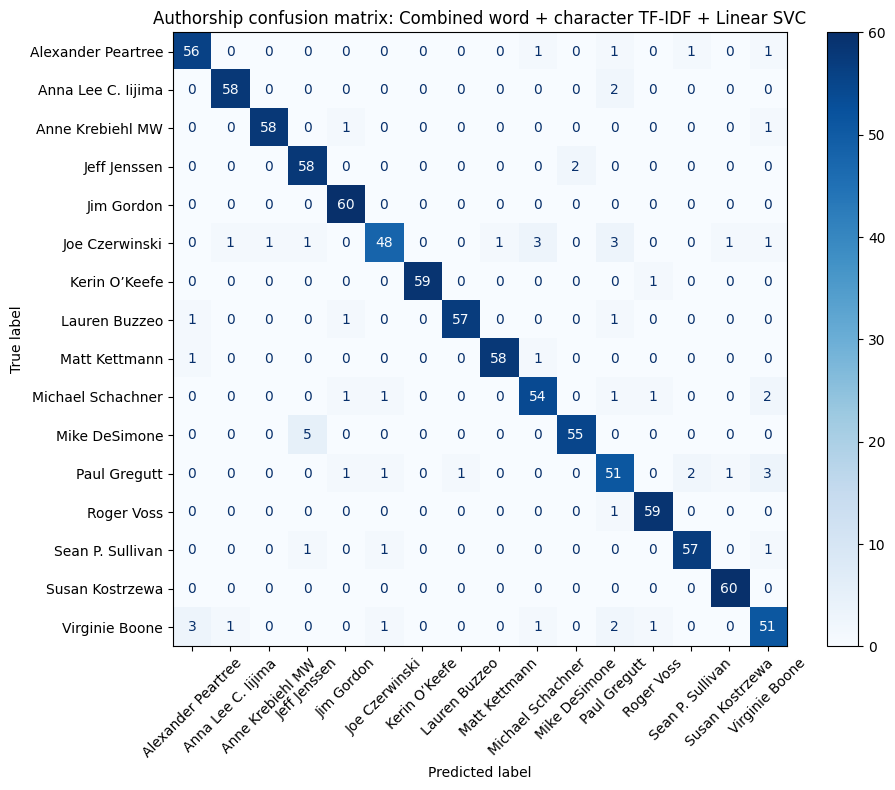

In [15]:
# Tune the combined model on training reviews only; metadata is never included.
# The word settings come from the preceding word-only search, while this search
# directly selects the character span and SVC regularization for the combined model.
combined_pipeline = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            stop_words="english", max_df=0.85, sublinear_tf=True,
            ngram_range=word_svc_grid.best_params_["tfidf__ngram_range"],
            min_df=word_svc_grid.best_params_["tfidf__min_df"],
        )),
        ("character", TfidfVectorizer(
            analyzer="char_wb", min_df=3, max_features=50000, sublinear_tf=True
        )),
    ])),
    ("svc", LinearSVC()),
])
combined_parameter_grid = {
    "features__character__ngram_range": [(2, 5), (3, 6), (4, 6)],
    "svc__C": [0.1, 0.5, 1, 2, 5],
}
combined_grid = GridSearchCV(
    combined_pipeline, combined_parameter_grid, scoring="f1_macro", cv=cv, n_jobs=-1
)
combined_grid.fit(X_train, y_train)
best_combined_svc = combined_grid.best_estimator_
combined_pred = best_combined_svc.predict(X_test)
best_char_settings = {
    key: value for key, value in combined_grid.best_params_.items()
    if key.startswith("features__character") or key == "svc__C"
}
print("Best combined-model CV macro F1:", f"{combined_grid.best_score_:.1%}")
print("Best combined-model settings:", combined_grid.best_params_)

# Evaluate the selected character settings alone for a like-for-like comparison.
char_tfidf = TfidfVectorizer(
    analyzer="char_wb", ngram_range=best_char_settings["features__character__ngram_range"],
    min_df=3, max_features=50000, sublinear_tf=True
)
X_train_char = char_tfidf.fit_transform(X_train)
X_test_char = char_tfidf.transform(X_test)
char_svc = LinearSVC(C=best_char_settings["svc__C"])
char_svc.fit(X_train_char, y_train)
char_pred = char_svc.predict(X_test_char)

style_results = pd.DataFrame({
    "model": ["Character TF-IDF + Linear SVC", "Combined word + character TF-IDF + Linear SVC"],
    "accuracy": [accuracy_score(y_test, char_pred), accuracy_score(y_test, combined_pred)],
    "macro_f1": [
        f1_score(y_test, char_pred, average="macro"),
        f1_score(y_test, combined_pred, average="macro"),
    ],
})
model_results = pd.concat([model_results, style_results], ignore_index=True)
print("All model results")
display(model_results.style.format({"accuracy": "{:.1%}", "macro_f1": "{:.1%}"}))

# Use the best-scoring final model for the predictive confusion matrix.
final_model_name = model_results.loc[model_results["macro_f1"].idxmax(), "model"]
final_predictions = {
    "Tuned word TF-IDF + Linear SVC": word_svc_pred,
    "Character TF-IDF + Linear SVC": char_pred,
    "Combined word + character TF-IDF + Linear SVC": combined_pred,
}.get(final_model_name, log_pred)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_predictions, display_labels=np.sort(y.unique()), cmap="Blues", xticks_rotation=45, ax=ax
)
ax.set_title(f"Authorship confusion matrix: {final_model_name}")
plt.tight_layout()
plt.show()


## Cross-Validate the Tuned Combined Model
The combined model's character span and SVC regularization were selected using only the training split. This cell reports five-fold stratified CV for that selected configuration across the full balanced text-only dataset.

In [16]:
from sklearn.model_selection import cross_val_score

# Cloning the tuned pipeline prevents TF-IDF vocabulary leakage between folds.
final_combined_pipeline = clone(best_combined_svc)

combined_cv_scores = cross_val_score(
    final_combined_pipeline, X, y, scoring="f1_macro", cv=cv, n_jobs=-1
)

combined_cv_results = pd.DataFrame({
    "fold": range(1, len(combined_cv_scores) + 1),
    "macro_f1": combined_cv_scores,
})
display(combined_cv_results.style.format({"macro_f1": "{:.1%}"}))
print(
    "Combined model cross-validation macro F1:",
    f"{combined_cv_scores.mean():.1%} ± {combined_cv_scores.std():.1%}",
)


,fold,macro_f1
0,1,94.9%
1,2,94.9%
2,3,95.0%
3,4,95.0%
4,5,95.0%


Combined model cross-validation macro F1: 94.9% ± 0.1%


## 4. U.S.-Only Control

Country is held constant by using only U.S.-labeled wine reviews.


In [17]:
# COUNTRY CONTROL: only U.S.-labeled wines from four U.S.-focused reviewers.
US_AUTHORS = ["Matt Kettmann", "Paul Gregutt", "Sean P. Sullivan", "Virginie Boone"]
us_data = balanced[
    balanced["taster_name"].isin(US_AUTHORS) & balanced["country"].eq("US")
].copy()
us_sample_size = us_data["taster_name"].value_counts().min()
us_data = (
    us_data.groupby("taster_name", group_keys=False)
    .sample(n=us_sample_size, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

X_us = us_data["description"]
y_us = us_data["taster_name"]
X_train_us, X_test_us, y_train_us, y_test_us = train_test_split(
    X_us, y_us, test_size=0.20, stratify=y_us, random_state=RANDOM_STATE
)

us_dummy = DummyClassifier(strategy="most_frequent").fit(X_train_us, y_train_us)
us_model = clone(best_word_svc).fit(X_train_us, y_train_us)
us_pred = us_model.predict(X_test_us)

us_results = pd.DataFrame({
    "model": ["Dummy baseline", "Tuned word TF-IDF + Linear SVC"],
    "accuracy": [accuracy_score(y_test_us, us_dummy.predict(X_test_us)), accuracy_score(y_test_us, us_pred)],
    "macro_f1": [
        f1_score(y_test_us, us_dummy.predict(X_test_us), average="macro", zero_division=0),
        f1_score(y_test_us, us_pred, average="macro"),
    ],
})
print(f"U.S.-only control: {len(us_data):,} reviews; {us_sample_size} per reviewer")
display(us_results.style.format({"accuracy": "{:.1%}", "macro_f1": "{:.1%}"}))


U.S.-only control: 1,176 reviews; 294 per reviewer


,model,accuracy,macro_f1
0,Dummy baseline,25.0%,10.0%
1,Tuned word TF-IDF + Linear SVC,95.8%,95.8%


## 5. Metadata-Masked Control

Each review has its own province, region, and variety labels removed from the text before modeling.


In [18]:
# METADATA-MASKED CONTROL: remove each review's matching province, region, and variety terms.
# Short values such as "US" are intentionally not removed because they can match ordinary words.
METADATA_COLUMNS = ["country", "province", "region_1", "region_2", "variety"]

def mask_metadata_terms(row):
    text = row["description"]
    for column in METADATA_COLUMNS:
        value = row.get(column)
        if pd.notna(value):
            value = str(value).strip()
            if len(value) > 2:
                text = re.sub(r"(?<!\w)" + re.escape(value) + r"(?!\w)", " [MASK] ", text, flags=re.IGNORECASE)
    return text

masked_text = balanced.apply(mask_metadata_terms, axis=1)
X_train_masked, X_test_masked, y_train_masked, y_test_masked = train_test_split(
    masked_text, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
masked_model = clone(best_word_svc).fit(X_train_masked, y_train_masked)
masked_pred = masked_model.predict(X_test_masked)

masked_results = pd.DataFrame({
    "model": ["Tuned word TF-IDF + Linear SVC after metadata masking"],
    "accuracy": [accuracy_score(y_test_masked, masked_pred)],
    "macro_f1": [f1_score(y_test_masked, masked_pred, average="macro")],
})
print("Metadata-masked control")
display(masked_results.style.format({"accuracy": "{:.1%}", "macro_f1": "{:.1%}"}))


Metadata-masked control


,model,accuracy,macro_f1
0,Tuned word TF-IDF + Linear SVC after metadata masking,91.8%,91.8%


## 6. Logistic Regression Interpretation

Top coefficient terms are model associations, not automatically proof of personal style.


In [19]:
# Logistic regression remains the interpretable model: its coefficients show author-associated terms.
feature_names = np.array(log_tfidf.get_feature_names_out())
term_rows = []
for author, coefficients in zip(log_reg.classes_, log_reg.coef_):
    top_indices = coefficients.argsort()[::-1][:12]
    for rank, index in enumerate(top_indices, start=1):
        term_rows.append({"reviewer": author, "rank": rank, "term": feature_names[index]})

model_top_terms = pd.DataFrame(term_rows)
display(model_top_terms.pivot(index="rank", columns="reviewer", values="term"))

print("Per-reviewer Logistic Regression results")
log_report = pd.DataFrame(classification_report(y_test, log_pred, output_dict=True, zero_division=0)).T
per_reviewer_results = log_report.loc[log_reg.classes_, ["precision", "recall", "f1-score", "support"]]
display(per_reviewer_results.style.format({
    "precision": "{:.1%}", "recall": "{:.1%}", "f1-score": "{:.1%}", "support": "{:.0f}"
}))


reviewer,Alexander Peartree,Anna Lee C. Iijima,Anne Krebiehl MW,Jeff Jenssen,Jim Gordon,Joe Czerwinski,Kerin O’Keefe,Lauren Buzzeo,Matt Kettmann,Michael Schachner,Mike DeSimone,Paul Gregutt,Roger Voss,Sean P. Sullivan,Susan Kostrzewa,Virginie Boone
rank,,,,,,,,,,,,,,,,
1,nose,riesling,freshness,cherry,texture,hints,alongside,mouth,bottling,berry,violet,cherry fruit,wine,aromas,spice,oak
2,palate,acidity,palate,lemon,like,drink,palate offers,medium,nose,aromas,tannins,mix,fruits,feel,pair,tannin
3,tones,dry,aromatic,freshly,bodied,finish drink,offers,medium weight,shows,feels,bright,fruit,acidity,fruit flavors,elegant,site
4,bodied palate,lend,slender,mouth,bodied wine,shiraz,palate delivers,weight,nose bottling,flavors,flavors,vineyard,drink,herb,character,wine
5,berries,brisk,ripe,aromas,flavors,bodied,palate,close,black,plum,bouquet,barrel,attractive,barrel,followed,bodied
6,light bodied,tangerine,fresh,colored,wine,years,opens,sweet spice,slate,finish,finish,alcohol,aftertaste,notes,overall,vineyard
7,nose palate,mineral,notes,juice,aroma,long,note,drink,sagebrush,herbal,eucalyptus,acids,ripe,herbs,friendly,grown
8,peach,penetrating,dry,garnet,tastes,slightly,delivers,clean,sip,fruits,black cherry,washington,character,followed,nose,taste
9,carry,tones,nose,black,great,notes,aromas,accents,palate,oaky,cherry,oregon,ready,brings,balanced,estate


Per-reviewer Logistic Regression results


,precision,recall,f1-score,support
Alexander Peartree,88.3%,88.3%,88.3%,60
Anna Lee C. Iijima,95.0%,95.0%,95.0%,60
Anne Krebiehl MW,90.0%,90.0%,90.0%,60
Jeff Jenssen,87.5%,93.3%,90.3%,60
Jim Gordon,86.2%,93.3%,89.6%,60
Joe Czerwinski,85.4%,68.3%,75.9%,60
Kerin O’Keefe,100.0%,96.7%,98.3%,60
Lauren Buzzeo,94.6%,88.3%,91.4%,60
Matt Kettmann,94.8%,91.7%,93.2%,60
Michael Schachner,84.1%,88.3%,86.2%,60
